**Import Libraries**

In [126]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from datetime import datetime

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

print('Successfully imported modules...')

Successfully imported modules...


**Initial Look on the Data**

In [115]:
# create dataframe

file_path = r'/content/social-media-sentiments-analysis/dataset/sentimentdataset.csv'

df = pd.read_csv(file_path)

print('Successfully created dataframe...')

Successfully created dataframe...


In [116]:
# df metadata

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [117]:
# first fop rows
print('Top 5 Rows: ')
display(df.head())
print('\nLast 5 Rows:')
display(df.tail())

Top 5 Rows: 


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19



Last 5 Rows:


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
727,728,732,Collaborating on a science project that receiv...,Happy,2017-08-18 18:20:00,ScienceProjectSuccessHighSchool,Facebook,#ScienceFairWinner #HighSchoolScience,20.0,39.0,UK,2017,8,18,18
728,729,733,Attending a surprise birthday party organized ...,Happy,2018-06-22 14:15:00,BirthdayPartyJoyHighSchool,Instagram,#SurpriseCelebration #HighSchoolFriendship,25.0,48.0,USA,2018,6,22,14
729,730,734,Successfully fundraising for a school charity ...,Happy,2019-04-05 17:30:00,CharityFundraisingTriumphHighSchool,Twitter,#CommunityGiving #HighSchoolPhilanthropy,22.0,42.0,Canada,2019,4,5,17
730,731,735,"Participating in a multicultural festival, cel...",Happy,2020-02-29 20:45:00,MulticulturalFestivalJoyHighSchool,Facebook,#CulturalCelebration #HighSchoolUnity,21.0,43.0,UK,2020,2,29,20
731,732,736,Organizing a virtual talent show during challe...,Happy,2020-11-15 15:15:00,VirtualTalentShowSuccessHighSchool,Instagram,#VirtualEntertainment #HighSchoolPositivity,24.0,47.0,USA,2020,11,15,15


In [118]:
# return each number of unique values per column
df.nunique().sort_values(ascending=False)

,0
Unnamed: 0.1,732
Unnamed: 0,732
Text,707
Hashtags,697
User,685
Timestamp,683
Sentiment,279
Country,115
Likes,38
Day,31


In [119]:
# descriptive statisticsfor num cols
df.describe().round(2).map(lambda x: f'{x:g}')

,Unnamed: 0.1,Unnamed: 0,Retweets,Likes,Year,Month,Day,Hour
count,732,732,732,732,732,732,732,732
mean,366.46,369.74,21.51,42.9,2020.47,6.12,15.5,15.52
std,211.51,212.43,7.06,14.09,2.8,3.41,8.47,4.11
min,0,0,5,10,2010,1,1,0
25%,183.75,185.75,17.75,34.75,2019,3,9,13
50%,366.5,370.5,22,43,2021,6,15,16
75%,549.25,553.25,25,50,2023,9,22,19
max,732,736,40,80,2023,12,31,23


In [120]:
# descriptive statistics for cat cols
df.describe(include='O').T

,count,unique,top,freq
Text,732,707,"A compassionate rain, tears of empathy fallin...",3
Sentiment,732,279,Positive,44
Timestamp,732,683,2019-04-05 17:30:00,3
User,732,685,WinterWarmth,3
Platform,732,4,Instagram,258
Hashtags,732,697,#Hopeful #SeedsOfOptimism,3
Country,732,115,USA,59


**Data Quality**

In [121]:
# to prevent alteration
data = df.copy()

print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB
None


In [122]:
# drop columns
data = data.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

row, col = data.shape
print(f'Total Number of Rows: {row}')
print(f'Total Number of Columns: {col}')
print('Successfully dropped columns...')

Total Number of Rows: 732
Total Number of Columns: 13
Successfully dropped columns...


In [149]:
# check if df has duplicates
has_duplicates = data.duplicated().any()
print(f'Are there duplicates in the dataset?: {has_duplicates}')

duplicate_count = data.duplicated().sum()
print(f'Number of duplicates: {duplicate_count}')

Are there duplicates in the dataset?: True
Number of duplicates: 21


In [152]:
data[data.duplicated(subset=['Text'], keep=False)]

,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
264,"A compassionate rain, tears of empathy fallin...",Compassionate,2021-07-01 12:10:00,RainNurturer,Facebook,#Compassionate #TearsOfEmpathy,21.0,42.0,Canada,2021,7,1,12
265,"Proudly scaling the peaks of achievement, a m...",Proud,2020-01-05 08:45:00,PeakConqueror,Twitter,#Proud #ScalingPeaks,23.0,46.0,USA,2020,1,5,8
266,"Embraced by the hopeful dawn, a gardener sowi...",Hopeful,2022-07-17 06:15:00,DawnGardener,Instagram,#Hopeful #SeedsOfOptimism,14.0,28.0,UK,2022,7,17,6
267,"A playful escapade in the carnival of life, c...",Playful,2018-08-22 17:20:00,CarnivalDreamer,Facebook,#Playful #CarnivalEscapade,24.0,48.0,Australia,2018,8,22,17
268,"Floating on clouds of inspiration, an artist ...",Inspired,2021-12-08 14:30:00,SkyArtist,Twitter,#Inspired #CloudsOfCreativity,18.0,36.0,India,2021,12,8,14
269,"Navigating the river of contentment, a serene...",Contentment,2019-04-27 09:50:00,RiverNavigator,Instagram,#Contentment #TranquilWaters,20.0,40.0,Canada,2019,4,27,9
270,"With empathy as a lantern, wandering through ...",Empathetic,2023-09-03 21:40:00,LanternWanderer,Facebook,#Empathetic #LanternOfCompassion,16.0,32.0,USA,2023,9,3,21
271,"A free spirit soaring on the wings of dreams,...",Free-spirited,2020-06-10 10:05:00,DreamSoarer,Twitter,#FreeSpirit #WingsOfDreams,22.0,44.0,UK,2020,6,10,10
272,"Bathed in the golden hues of gratefulness, a ...",Grateful,2022-04-01 18:30:00,SunsetAdmirer,Instagram,#Grateful #GoldenHues,19.0,38.0,Australia,2022,4,1,18
273,"Confident strides in the dance of life, a bal...",Confident,2021-01-15 13:00:00,DanceStrider,Facebook,#Confident #DanceOfLife,23.0,46.0,Canada,2021,1,15,13


In [155]:
# drop duplicates
data = data.drop_duplicates()

print("You have successfully dropped duplicates in the dataset...\n")
print('Count of rows after removing duplicates', len(data))
print('Count of duplicates in the dataset:', data.duplicated().sum())

You have successfully dropped duplicates in the dataset...

Count of rows after removing duplicates 711
Count of duplicates in the dataset: 0


In [156]:
# Check for missing values
any_missing = data.isnull().any().sort_values(ascending=False)
print("Missing value status per column:")
print(any_missing)

missing_count = data.isnull().sum().sort_values(ascending=False)
print("\nMissing value count per column:")
print(missing_count)

Missing value status per column:
Text         False
Sentiment    False
Timestamp    False
User         False
Platform     False
Hashtags     False
Retweets     False
Likes        False
Country      False
Year         False
Month        False
Day          False
Hour         False
dtype: bool

Missing value count per column:
Text         0
Sentiment    0
Timestamp    0
User         0
Platform     0
Hashtags     0
Retweets     0
Likes        0
Country      0
Year         0
Month        0
Day          0
Hour         0
dtype: int64


In [158]:
# inspect data types
df.dtypes

,0
Unnamed: 0.1,int64
Unnamed: 0,int64
Text,object
Sentiment,object
Timestamp,object
User,object
Platform,object
Hashtags,object
Retweets,float64
Likes,float64


In [129]:
# convert timestamp to datetime
data['Timestamp'] = pd.to_datetime(data['Timestamp'])

# inspect conversion
data['Timestamp'].dtype

dtype('<M8[ns]')

In [159]:
# address inconsistencies
cols = data[['Sentiment', 'Country', 'Platform']]

for col in cols:
  data[col] = data[col].str.strip()

  print(f'{col}:')
  print(data[col].value_counts(dropna=False).to_string(header=False))
  print("=====" * 10)

Sentiment:
Positive                45
Joy                     44
Excitement              37
Contentment             18
Neutral                 18
Gratitude               17
Curiosity               16
Serenity                15
Happy                   14
Despair                 11
Nostalgia               11
Awe                      9
Grief                    9
Sad                      9
Acceptance               8
Loneliness               8
Embarrassed              8
Confusion                8
Determination            7
Euphoria                 7
Enthusiasm               7
Pride                    7
Elation                  7
Ambivalence              6
Hopeful                  6
Frustration              6
Numbness                 6
Surprise                 6
Melancholy               6
Regret                   6
Indifference             6
Hate                     6
Bad                      6
Bitterness               5
Inspiration              5
Hope                     5
Empowerment      

**Exploratory Data Analysis**

In [165]:
# inspect numerical cols
data[['Retweets', 'Likes']].describe().round(2).map(lambda x: f'{x:g}').T

,count,mean,std,min,25%,50%,75%,max
Retweets,711,21.53,7.13,5,17.5,22,25,40
Likes,711,42.95,14.22,10,34.5,43,50,80


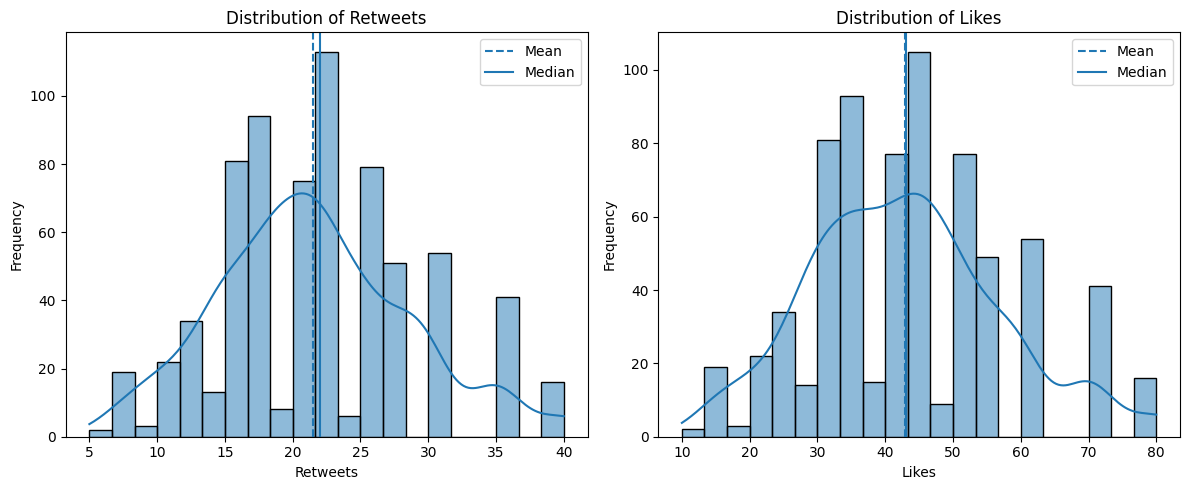

In [187]:
# Plot histograms
num_cols = data[['Retweets', 'Likes']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, num_cols):

    sns.histplot(data=data, x=col, kde=True, ax=ax)

    ax.axvline(data[col].mean(), linestyle='--', label='Mean')
    ax.axvline(data[col].median(), linestyle='-', label='Median')

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.show()

In [179]:
# inspect for outliers
def main():

  identify_outliers()

def identify_outliers():

  q1 = num_cols.quantile(0.25)
  q3 = num_cols.quantile(0.75)

  iqr = q3 - q1

  lower_limit = q1 - 1.5 * iqr
  upper_limit = q3 + 1.5 * iqr

  for col in num_cols:

    lower_outliers = num_cols[col][num_cols[col] < lower_limit[col]]
    upper_outliers = num_cols[col][num_cols[col] > upper_limit[col]]


    print(f'{col}:')

    print(f'Number of Lower Outliers: {len(lower_outliers)}')
    print(f'Lower Limit: {lower_limit[col]}')
    print(f'Lower Outliers: {lower_outliers.tolist()}')


    print(f'Number of Upper Outliers: {len(upper_outliers)}')
    print(f'Upper Limit: {upper_limit[col]}')
    print(f'Upper Outliers: {upper_outliers.tolist()}')


    print("=====" * 25)

main()

Retweets:
Number of Lower Outliers: 2
Lower Limit: 6.25
Lower Outliers: [5.0, 5.0]
Number of Upper Outliers: 16
Upper Limit: 36.25
Upper Outliers: [40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0]
Likes:
Number of Lower Outliers: 2
Lower Limit: 11.25
Lower Outliers: [10.0, 10.0]
Number of Upper Outliers: 16
Upper Limit: 73.25
Upper Outliers: [80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0, 80.0]


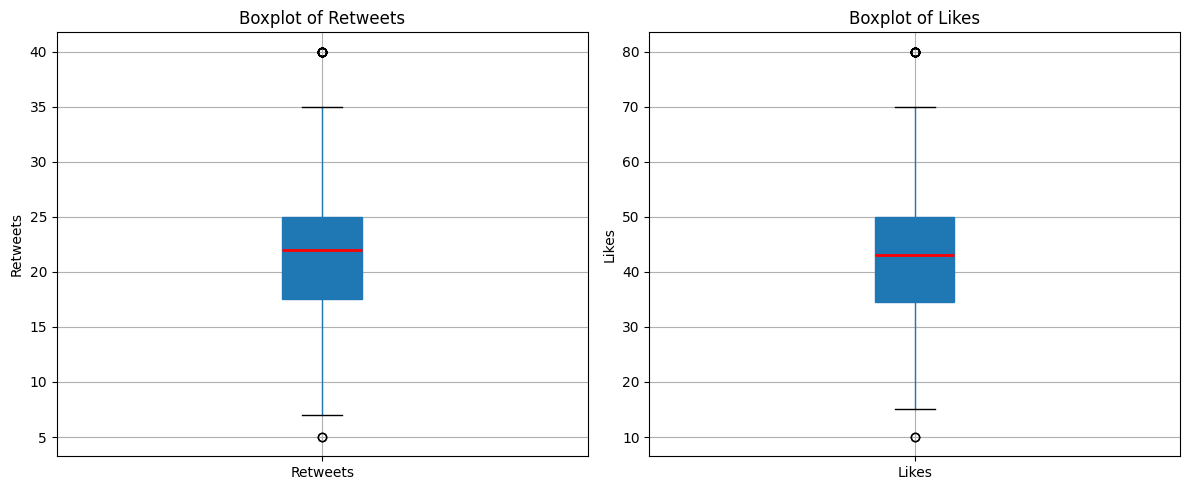

In [188]:
# plot boxplot

fig, axes = plt.subplots(1, 2, figsize=(12,5))

for ax, col in zip(axes, num_cols):

  data.boxplot(
               column=[col],
               ax=ax,
               patch_artist=True,
               medianprops={
                   'color': 'red',
                   'linewidth': 2
                   }
               )

  ax.set_title(f'Boxplot of {col}')
  ax.set_ylabel(col)

plt.tight_layout()
plt.show()